# EDA и бейзлайн прогнозирования аффинности

По структуре малой молекулы предсказываем силу её взаимодействия с белковой мишенью.

**Малая молекула** в этом проекте — органическое соединение с относительно небольшой молекулярной массой. Её **структура** описывает, какие атомы входят в состав молекулы и какими химическими связями они соединены.

**SMILES** — текстовый формат записи химической структуры: буквы обозначают атомы, специальные символы — связи, скобки — ответвления, а цифры указывают замыкание колец.

Например, [кофеин](https://pubchem.ncbi.nlm.nih.gov/compound/caffeine) состоит из атомов углерода, водорода, азота и кислорода; его структуру можно записать в формате SMILES: `Cn1c(=O)c2c(ncn2C)n(C)c1=O`.

**Белковая мишень** — белок, связывание с которым может изменять его активность. Белок представляет собой молекулу, построенную из аминокислот. В проекте рассматриваем отдельные человеческие белки. Например, [аденозиновый рецептор A2A](https://www.ncbi.nlm.nih.gov/gene/135) — белок на мембране клетки, который воспринимает сигнал аденозина и передаёт его внутрь клетки.

**pKi** — логарифмическая мера силы связывания. pKi = 7 соответствует Ki = 100 нМ, pKi = 6 — Ki = 1 мкМ. Большее pKi означает более сильное взаимодействие.

## Что есть в данных и что использует модель

Источник — ChEMBL. **Исходная строка — результат одного эксперимента для молекулы и биологической мишени.** Для обучения отбираем отдельные человеческие белки. После очистки строка в `pairs.parquet` — уникальная пара «структура молекулы — мишень» с медианой повторных измерений. Структуры и их свойства хранятся отдельно в `molecules.parquet`.

Основные поля исходной выгрузки и присоединённых аннотаций:

| Поле | Что означает | Как используем и почему |
|---|---|---|
| `canonical_smiles` → `smiles` | Текстовая запись атомов, связей и стереохимии молекулы; `smiles` — результат нашей обработки | Источник входных признаков: структура определяет, какие взаимодействия молекула может образовывать с белком |
| `standard_type`, `standard_value`, `standard_units`, `standard_relation` | Вид, числовое значение, единицы и знак измерения; например, Ki = 100 нМ | Отбираем точные Ki в нМ и рассчитываем **целевую величину** `pki = 9 − log10(Ki в нМ)` |
| `pchembl_value` | Готовая логарифмическая мера активности ChEMBL; для выбранных Ki соответствует pKi | Проверяем пересчёт. Результаты измерения используются как ответ модели, а подача их на вход создала бы утечку ответа |
| `target_chembl_id`, название мишени | Какой белок исследовали | Выбирают отдельный лес или выход будущей многозадачной сети. ID служит меткой задачи и не описывает строение белка |
| `assay_type`, `target_type`, организм, `confidence_score`, аннотация мутации | Тип теста, тип и вид мишени, уверенность её сопоставления и сведения о варианте белка | Фильтруем сопоставимые эксперименты: связывание, отдельный человеческий белок, уверенность 9, без аннотированной мутации |
| `data_validity_comment`, `standard_flag`, `potential_duplicate` | Комментарии и флаги качества измерения и возможного дубликата | Используем при очистке; они описывают качество записи |
| ID молекулы, измерения, теста и документа; `document_year` | Идентификаторы происхождения записи и год публикации | Связываем таблицы, проверяем повторы и историю данных. На вход модели не подаём: по ним нельзя описать новую структуру |

Из SMILES с помощью RDKit дополнительно рассчитываем свойства молекул. Они нужны для EDA: показывают, какие соединения представлены и где встречаются необычные значения.

| Поле в `molecules.parquet` | Что означает | Что помогает проверить |
|---|---|---|
| `molecular_weight`, `heavy_atoms` | Молекулярная масса в Да и число атомов, кроме водорода | Размер молекул; чрезмерно крупные соединения |
| `logp` | Расчётный logP — мера предпочтения жировой среды водной | Липофильность и её диапазон |
| `tpsa` | Расчётная топологическая полярная площадь, Å² | Выраженность полярных участков молекулы |
| `hbd`, `hba` | Число доноров и акцепторов водородной связи | Возможности образования водородных связей |
| `rotatable_bonds`, `rings` | Число вращаемых связей и колец | Гибкость и кольцевое строение молекул |

**Вход Random Forest — только 2048 Morgan-битов**, рассчитанных из `smiles`: 0/1 кодируют наличие локальных окружений атомов в радиусе двух связей, с учётом стереохимии. Это фиксированный числовой вектор, удобный для леса и сохраняющий сведения о подструктурах. Дескрипторы выше используем для анализа; такой выбор оставляет одно простое представление в бейзлайне. Пользу добавления дескрипторов можно проверить отдельным экспериментом. Сам SMILES лес не читает.

**Для будущей GNN** планируем использовать ту же структуру как граф: узлы — атомы (элемент, заряд, ароматичность), рёбра — связи (тип, стереохимия). Сеть будет сама обучать представление молекулы и выдавать pKi для фиксированного набора мишеней. Последовательности и 3D-структуры белков в текущий вход не входят.

Остальные поля — служебные: `compound_id`, `molecule_index` связывают таблицы и строки fingerprints; `connectivity`, `scaffold` и поля `*_split` задают разбиения; `benchmark_target` отмечает включённые в сравнение мишени. `n_measurements`, `n_assays`, `n_documents`, `pki_min`, `pki_max`, `repeat_range`, `first_year`, `last_year` описывают повторы и публикации, а `fragment_removed` — удаление фрагмента соли. Эти поля помогают аудиту и оценке и не подаются в модель.

Определения: [поля измерений ChEMBL](https://chembl.gitbook.io/chembl-interface-documentation/frequently-asked-questions/chembl-data-questions), [Morgan fingerprints в RDKit](https://www.rdkit.org/docs/GettingStartedInPython.html#morgan-fingerprints-circular-fingerprints).

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown
from affinity_eda import (prepare_data, get_fingerprints, fingerprint_audit, fingerprint_sensitivity, approved_coverage, train_benchmark,
                          augmentation_invariance, explain_baseline, CFG, RESULTS, DATA)
from eda_figures import generate_figures
pd.set_option('display.max_colwidth', 55)
pd.set_option('display.precision', 3)
pairs, molecules, eda = prepare_data()
display(Markdown(f"**Источник:** {eda['source']['release']}. "
                 f"**Срез:** 25 октября 2026. **Случайное зерно:** {CFG['seed']}."))
display(pd.DataFrame({'Показатель': ['Исходных измерений', 'Пар после очистки', 'Молекул',
                                    'Мишеней после очистки', 'Мишеней для бейзлайна'],
                      'Число': [eda['raw_rows'], eda['curated_pairs'], eda['curated_molecules'],
                                eda['curated_targets'], eda['benchmark_targets']]}))
if (RESULTS / 'baseline_summary.json').exists():
    headline = json.loads((RESULTS / 'baseline_summary.json').read_text())
    display(Markdown(f"**Основной результат:** на новых химических каркасах MAE Random Forest = "
                     f"**{headline['test_macro_MAE']:.3f} pKi**; у среднего по мишени — "
                     f"**{headline['dummy_test_macro_MAE']:.3f}**. "
                     f"**Мишеней в проверке:** {headline['targets']}; **пар test:** {headline['test_pairs']:,}."))

**Источник:** ChEMBL_37. **Срез:** 25 октября 2026. **Случайное зерно:** 42.

,Показатель,Число
0,Исходных измерений,530618
1,Пар после очистки,204676
2,Молекул,120720
3,Мишеней после очистки,1197
4,Мишеней для бейзлайна,131


**Основной результат:** на новых химических каркасах MAE Random Forest = **0.585 pKi**; у среднего по мишени — **0.952**. **Мишеней в проверке:** 131; **пар test:** 16,665.

## Качество данных

Сохраняем только Ki из тестов связывания: прямое сопоставление с отдельным человеческим белком, уверенность аннотации 9, корректную структуру и точное положительное измерение в нМ.

Пропуски в условиях экспериментов означают отсутствие аннотации. Пропуск в матрице «молекула — мишень» означает **неизвестную активность**, его нельзя заменять нулём.

In [2]:
missing = pd.read_csv(RESULTS / 'raw_missingness.csv', index_col=0)
fields = {'canonical_smiles': 'Структура молекулы', 'standard_value': 'Числовое значение Ki',
          'pchembl_value': 'Готовое pChEMBL', 'document_year': 'Год публикации'}
display(missing.loc[list(fields), ['missing_fraction']].rename(index=fields, columns={'missing_fraction': 'Доля пропусков'}))
relation_missing = pd.read_csv(RESULTS / 'pchembl_missing_by_relation.csv', index_col=0)
display(Markdown(f"Доля незаполненных клеток матрицы взаимодействий: "
                 f"**{eda['matrix_missing_fraction']:.2%}**. "
                 f"Готовое pChEMBL отсутствует у **{relation_missing.loc['=', 'True']:.1%}** "
                 "точных измерений и у всех пороговых записей (<, > и т. п.). "
                 "Пороговые записи исключены: они не задают точное значение для обычной регрессии. "
                 "Отсутствие аннотации мутации не доказывает отсутствие мутации."))

,Доля пропусков
Структура молекулы,0.007
Числовое значение Ki,0.160
Готовое pChEMBL,0.290
Год публикации,0.146


Доля незаполненных клеток матрицы взаимодействий: **99.86%**. Готовое pChEMBL отсутствует у **2.2%** точных измерений и у всех пороговых записей (<, > и т. п.). Пороговые записи исключены: они не задают точное значение для обычной регрессии. Отсутствие аннотации мутации не доказывает отсутствие мутации.

In [3]:
display(pd.read_csv(RESULTS / 'cleaning_funnel.csv').rename(
    columns={'step': 'Шаг', 'remaining': 'Осталось измерений', 'removed': 'Исключено'}))
display(Markdown(f"После проверки качества **{eda['pki_check']['with_provided_pchembl']:,}** "
                 "пересчитанных pKi согласуются с pChEMBL (допуск 0,05). "
                 f"Из структур исключены: >100 тяжёлых атомов — {eda['structure_status']['over_100_heavy_atoms']:,}; "
                 f"несколько крупных органических компонентов — {eda['structure_status']['multiple_organic_components']:,}; "
                 "остальные причины — отсутствие органического фрагмента, неподдерживаемый элемент или ошибка SMILES."))

,Шаг,Осталось измерений,Исключено
0,Получено из API,530618,0
1,Точное измерение Ki,385463,145155
2,Положительное конечное значение в нМ,384996,467
3,Нет флага ошибки измерения,376983,8013
4,Нет флага возможного дубликата,332868,44115
5,Отдельный человеческий белок,318025,14843
6,Прямое сопоставление мишени с уверенностью 9,235097,82928
7,Нет аннотации мутантного белка,233155,1942
8,pKi согласуется с указанным pChEMBL,233155,0
9,Пригодная органическая структура до 100 тяжёлых атомов,226486,6669


После проверки качества **233,155** пересчитанных pKi согласуются с pChEMBL (допуск 0,05). Из структур исключены: >100 тяжёлых атомов — 1,539; несколько крупных органических компонентов — 1,516; остальные причины — отсутствие органического фрагмента, неподдерживаемый элемент или ошибка SMILES.

Соли обрабатываются выбором основного органического фрагмента; неоднозначные записи с двумя крупными органическими компонентами откладываются. Заряды, таутомерная форма и стереохимия сохраняются. Ограничение до 100 тяжёлых атомов задаёт область рассматриваемых органических соединений.

Повторы одной структуры и мишени объединяются медианой. Если разброс превышает 2 единицы pKi (более чем стократное различие Ki), пару исключаем из бейзлайна как противоречивую. Такие пары сохранены для разбора. Статистически необычное значение само по себе не удаляем: редкое сильное связывание может быть реальным.

In [4]:
display(Markdown(f"Пар с повторными измерениями: **{eda['repeats']['repeated_pairs']:,}**; "
                 f"исключено противоречивых пар: **{eda['repeats']['conflicting_pairs_over_2_pki']:,}**."))
display(Markdown(f"По правилу 1,5 межквартильного размаха отмечено "
                 f"**{eda['iqr_outlier_pairs']:,}** необычных значений pKi; это диагностический флаг. "
                 f"Диапазон после очистки: {eda['pki_min']:.2f}–{eda['pki_max']:.2f}."))
# Полные описательные статистики вычислены в prepare_data через describe(include='all').
statistics = pd.read_csv(RESULTS / 'molecule_describe.csv', index_col=0).loc[
    ['molecular_weight','logp','tpsa','heavy_atoms'], ['min','25%','50%','75%','max']]
statistics = pd.concat([pd.read_csv(RESULTS / 'pair_describe.csv', index_col=0).loc[['pki'], statistics.columns], statistics])
display(statistics.rename(index={'pki':'pKi','molecular_weight':'Масса, Да','logp':'logP',
                                  'tpsa':'Полярная площадь, Å²','heavy_atoms':'Тяжёлые атомы'},
                          columns={'min':'Минимум','25%':'Q1','50%':'Медиана','75%':'Q3','max':'Максимум'}).round(2))

Пар с повторными измерениями: **15,701**; исключено противоречивых пар: **891**.

По правилу 1,5 межквартильного размаха отмечено **184** необычных значений pKi; это диагностический флаг. Диапазон после очистки: 1.10–11.00.

,Минимум,Q1,Медиана,Q3,Максимум
pKi,1.10,6.17,7.13,8.06,11.00
"Масса, Да",26.02,361.57,428.41,500.25,1618.56
logP,-18.26,2.53,3.64,4.73,17.04
"Полярная площадь, Å²",0.00,55.71,81.16,109.50,753.32
Тяжёлые атомы,2.00,26.00,30.00,35.00,100.00


## Распределения и покрытие

Это регрессия, поэтому баланса классов нет. Важны распределение pKi и дисбаланс числа измерений между мишенями.

In [5]:
X = get_fingerprints(molecules)
fp_audit = fingerprint_audit(molecules, X)
display(pd.Series({'Битов в векторе': fp_audit['bits'],
                   'Медианное число активных битов': fp_audit['active_bits_median'],
                   'Постоянных признаков': fp_audit['constant_bits'],
                   'Разных структур сверх числа уникальных fingerprints': fp_audit['different_structures_with_same_fingerprint_excess']}, name='Значение').to_frame())
coverage = approved_coverage(pairs)
display(pd.Series({'Допущенных структур одобренных малых молекул': coverage['eligible_unique_small_molecule_structures'],
                   'Из них с измерением Ki в очищенном наборе': coverage['with_curated_Ki_measurement']}, name='Число').to_frame())
display(Markdown(f"Для экспериментов: **мишеней — {eda['benchmark_targets']}**, "
                 f"**размеченных пар — {eda['benchmark_pairs']:,}**. "
                 f"Требуется не менее {CFG['minimum_pairs_per_target']} пар на мишень "
                 "и достаточное покрытие во всех частях обоих разбиений. "
                 f"Число мишеней, исключённых из-за покрытия: {eda['targets_dropped_for_split_coverage']}."))

,Значение
Битов в векторе,2048.0
Медианное число активных битов,54.0
Постоянных признаков,0.0
Разных структур сверх числа уникальных fingerprints,1776.0


,Число
Допущенных структур одобренных малых молекул,2048
Из них с измерением Ki в очищенном наборе,525


Для экспериментов: **мишеней — 131**, **размеченных пар — 164,432**. Требуется не менее 300 пар на мишень и достаточное покрытие во всех частях обоих разбиений. Число мишеней, исключённых из-за покрытия: 1.

Разные структуры могут иметь одинаковый Morgan fingerprint: компактный вектор не сохраняет всю информацию о молекуле. Это ограничение представления. Ниже дополнительно проверяем ошибку без совпадающих отпечатков.

## Как проверяем модель

Во всех задачах одна молекула относится к одной части выборки. Случайное разбиение группирует соединения с одинаковой структурой без учёта стереохимии. Основное разбиение группирует по Bemis–Murcko-каркасу — центральной кольцевой структуре и связующим фрагментам. Все бескольцевые молекулы образуют отдельную общую группу.

Каркасы между train, validation и test не пересекаются. Это более строгая проверка переноса на новые структуры, хотя разные каркасы тоже могут быть химически похожи. Доли около 80/10/10 относятся к группам и могут отличаться по числу молекул.

In [6]:
split_rows = []
for split in ['random_split', 'scaffold_split']:
    for part in ['train','validation','test']:
        selected = molecules[split].eq(part)
        split_rows.append({'Разбиение': split, 'Часть': part,
                           'Молекул': int(selected.sum()),
                           'Пар бейзлайна': int((pairs.benchmark_target & pairs[split].eq(part)).sum())})
display(pd.DataFrame(split_rows).replace({'random_split':'Случайное','scaffold_split':'По каркасам',
                                         'train':'Обучение','validation':'Валидация','test':'Тест'}))
for split in ['random_split','scaffold_split']:
    groups = {part: set(molecules.loc[molecules[split].eq(part),'compound_id'])
              for part in ['train','validation','test']}
    assert not (groups['train'] & groups['validation'] or groups['train'] & groups['test'] or groups['validation'] & groups['test'])
for left,right in [('train','test'),('train','validation'),('validation','test')]:
    assert set(molecules.loc[molecules.scaffold_split.eq(left),'scaffold']).isdisjoint(
        molecules.loc[molecules.scaffold_split.eq(right),'scaffold'])
assert not pairs.duplicated(['compound_id','target_chembl_id']).any()
print('Повторяющихся пар и пересечений молекул нет; каркасы в основном разбиении не пересекаются.')

,Разбиение,Часть,Молекул,Пар бейзлайна
0,Случайное,Обучение,96546,131305
1,Случайное,Валидация,12081,16668
2,Случайное,Тест,12093,16459
3,По каркасам,Обучение,97148,132328
4,По каркасам,Валидация,11443,15439
5,По каркасам,Тест,12129,16665


Повторяющихся пар и пересечений молекул нет; каркасы в основном разбиении не пересекаются.


## Random Forest на Morgan fingerprints

Для каждой мишени обучается отдельный лес из 100 деревьев. Проверяем минимальный размер листа 1, 3 и 10; остальные параметры одинаковы. Выбор — по среднему MAE на validation основного разбиения.

**MAE** — средняя абсолютная ошибка pKi. Ошибка на 1 единицу соответствует десятикратному расхождению Ki. **RMSE** сильнее учитывает крупные ошибки. **Спирмен** показывает качество порядка предсказаний; для постоянного прогноза он не определён. Все основные метрики усредняются сначала внутри каждой мишени, затем между мишенями: большие задачи не подавляют малые. Простой контроль всегда предсказывает средний pKi обучающей части своей мишени.

In [7]:
# При первом запуске функция действительно обучает модели; повторный запуск использует
# завершённые эксперименты только при совпадении хешей данных и конфигурации.
baseline = train_benchmark(pairs, molecules, X)
metrics = pd.read_csv(RESULTS / 'metrics_macro.csv')
selection = json.loads((RESULTS / 'selection.json').read_text())
display(pd.Series(selection['validation_macro_MAE'], name='Validation MAE').to_frame())
display(Markdown(f"Выбрана конфигурация **{baseline['selected']}**. "
                 "Тестовые метрики не используются при выборе параметров."))
experiments = [baseline['selected'], 'RF_random', 'RF_dropout5']
table = metrics.loc[metrics.part.eq('test') & metrics.experiment.isin(experiments)].copy()
table = table.loc[table.model.eq('RF') | table.experiment.eq(baseline['selected'])]
table['Проверка'] = table['split'].map({'scaffold_split': 'Новые каркасы', 'random_split': 'Случайные молекулы'})
table['Модель'] = np.where(table.model.eq('Mean'), 'Среднее по мишени',
                           np.where(table.experiment.eq('RF_dropout5'), 'RF с шумом 5%', 'Random Forest'))
table = table[['Модель','Проверка','MAE','RMSE','Spearman']].round(3).reset_index(drop=True)
table['Spearman'] = table.Spearman.astype(object).where(table.Spearman.notna(), '—')
display(table.rename(columns={'Spearman':'Спирмен'}))

,Validation MAE
RF_leaf1,0.586
RF_leaf3,0.638
RF_leaf10,0.721


Выбрана конфигурация **RF_leaf1**. Тестовые метрики не используются при выборе параметров.

,Модель,Проверка,MAE,RMSE,Спирмен
0,RF с шумом 5%,Новые каркасы,0.594,0.774,0.672
1,Среднее по мишени,Новые каркасы,0.952,1.153,—
2,Random Forest,Новые каркасы,0.585,0.764,0.687
3,Random Forest,Случайные молекулы,0.498,0.666,0.785


In [8]:
detail = pd.read_csv(RESULTS / 'metrics_by_target.csv')
main = detail.loc[detail.experiment.eq(baseline['selected']) & detail.part.eq('test') & detail.model.eq('RF')]
ordered = main.sort_values('MAE')
examples = pd.concat([ordered.head(3), ordered.tail(3)]).drop_duplicates('target_id')
display(examples[['target_name','n','MAE','RMSE','Spearman']].rename(
    columns={'target_name':'Мишень','n':'Пар test','Spearman':'Спирмен'}).round(3).reset_index(drop=True))
random_mae = metrics.loc[metrics.experiment.eq('RF_random') & metrics.part.eq('test') & metrics.model.eq('RF'),'MAE'].iloc[0]
delta = baseline['test_macro_MAE'] - random_mae
display(Markdown(f"На новых каркасах MAE = **{baseline['test_macro_MAE']:.3f}**, "
                 f"у среднего по мишени — **{baseline['dummy_test_macro_MAE']:.3f}**. "
                 f"Отличие от случайного разбиения: **{delta:+.3f}**. "
                 f"Для трёх инициализаций MAE: **{baseline['three_seed_macro_MAE_mean']:.3f} ± "
                 f"{baseline['three_seed_macro_MAE_sd']:.3f}** (стандартное отклонение). "
                 "Это разброс обучения на одном разбиении, а не доверительный интервал обобщения."))

,Мишень,Пар test,MAE,RMSE,Спирмен
0,Tyrosine-protein kinase JAK3,70,0.233,0.601,0.539
1,Leucine-rich repeat serine/threonine-protein kinase 2,57,0.259,0.349,0.770
2,Serine/threonine-protein kinase ATR,68,0.285,0.467,0.680
3,Muscarinic acetylcholine receptor M2,70,0.897,1.062,0.826
4,Amine oxidase [flavin-containing] A,40,0.967,1.161,0.507
5,Amine oxidase [flavin-containing] B,34,1.012,1.184,0.606


На новых каркасах MAE = **0.585**, у среднего по мишени — **0.952**. Отличие от случайного разбиения: **+0.086**. Для трёх инициализаций MAE: **0.584 ± 0.001** (стандартное отклонение). Это разброс обучения на одном разбиении, а не доверительный интервал обобщения.

In [9]:
sensitivity = fingerprint_sensitivity(pairs, molecules, X, baseline)
display(Markdown(f"В основном тесте **{sensitivity['test_pairs_with_fingerprint_seen_for_same_target']}** пар "
                 "имеют такой же fingerprint, как обучающий пример для той же мишени. "
                 f"После исключения этих случаев только из диагностического расчёта MAE = "
                 f"**{sensitivity['macro_MAE_without_shared_fingerprints']:.3f}** "
                 f"Число мишеней осталось прежним: {sensitivity['targets_remaining']}. "
                 "Основное разбиение и выбор параметров не меняются."))

В основном тесте **120** пар имеют такой же fingerprint, как обучающий пример для той же мишени. После исключения этих случаев только из диагностического расчёта MAE = **0.587** Число мишеней осталось прежним: 131. Основное разбиение и выбор параметров не меняются.

## Интерпретация признаков

Для наиболее представленной мишени проверяем важные биты: перемешиваем каждый признак на validation и смотрим, насколько ухудшится MAE. Положительное изменение означает, что признак помогал модели на этой выборке. Один бит может кодировать несколько подструктур из-за хеширования; его важность не доказывает механизм связывания.

In [10]:
interpretation = explain_baseline(pairs, molecules, X, baseline)
display(Markdown(f"Мишень для примера: **{interpretation['target_name']}**."))
display(pd.read_csv(RESULTS / 'feature_importances.csv').sort_values('permutation_MAE_increase', ascending=False)
        .head(5)[['bit','permutation_MAE_increase']].rename(
            columns={'bit':'Бит','permutation_MAE_increase':'Увеличение MAE'}).round(4))
display(pd.read_csv(RESULTS / 'fingerprint_bit_examples.csv').drop_duplicates('bit')
        .head(5)[['bit','radius','fragment']].rename(columns={'bit':'Бит','radius':'Радиус','fragment':'Пример фрагмента (SMILES)'}))

Мишень для примера: **Carbonic anhydrase 2**.

,Бит,Увеличение MAE
1,1607,0.014
9,926,0.013
0,1171,0.012
4,1489,0.011
3,833,0.010


,Бит,Радиус,Пример фрагмента (SMILES)
0,1171,0,N
1,1607,1,NS
2,1476,1,O=S
3,833,1,cS(N)(=O)=O
4,1489,2,ccc(cc)S(N)(=O)=O


## Проверка аугментаций

1. Случайные SMILES меняют текстовую запись той же молекулы.
2. Перестановка индексов атомов меняет порядок хранения того же графа.
3. Дополнительно обучаем лес с удалением 5% активных битов train. Это шум в признаках; он не гарантирует соответствия реальной молекуле и рассматривается только как диагностический эксперимент.

In [11]:
augmentation = augmentation_invariance(molecules)
display(pd.DataFrame({'Способ': ['Случайные SMILES','Перестановка атомов'],
                      'Проверок': [augmentation['trials_per_method']]*2,
                      'Совпавших fingerprints': [augmentation['random_smiles_identical_fingerprints'],
                                               augmentation['atom_permutation_identical_fingerprints']]}))
comparison = metrics.loc[metrics.experiment.isin([baseline['selected'],'RF_dropout5']) & metrics.model.eq('RF'),
                         ['experiment','part','MAE','RMSE']]
display(comparison.rename(columns={'experiment':'Эксперимент','part':'Часть'}).round(3))
noise_mae = comparison.loc[comparison.experiment.eq('RF_dropout5') & comparison.part.eq('test'), 'MAE'].iloc[0]
display(Markdown(f"Шум в битах изменил тестовую MAE на **{noise_mae - baseline['test_macro_MAE']:+.3f} pKi** "
                 "(плюс означает ухудшение)."))
display(Markdown('Одинаковые fingerprints не добавляют лесу новых структурных признаков. '
                 'Для будущей молекулярной GNN эти преобразования полезны как проверка '
                 'инвариантности; случайные SMILES могут быть полезны модели, читающей SMILES. '
                 'Основной бейзлайн фиксируется без искусственного удаления битов.'))

,Способ,Проверок,Совпавших fingerprints
0,Случайные SMILES,2500,2500
1,Перестановка атомов,2500,2500


,Эксперимент,Часть,MAE,RMSE
1,RF_dropout5,test,0.594,0.774
3,RF_dropout5,validation,0.596,0.773
5,RF_leaf1,test,0.585,0.764
7,RF_leaf1,validation,0.586,0.760


Шум в битах изменил тестовую MAE на **+0.010 pKi** (плюс означает ухудшение).

Одинаковые fingerprints не добавляют лесу новых структурных признаков. Для будущей молекулярной GNN эти преобразования полезны как проверка инвариантности; случайные SMILES могут быть полезны модели, читающей SMILES. Основной бейзлайн фиксируется без искусственного удаления битов.

## Графики

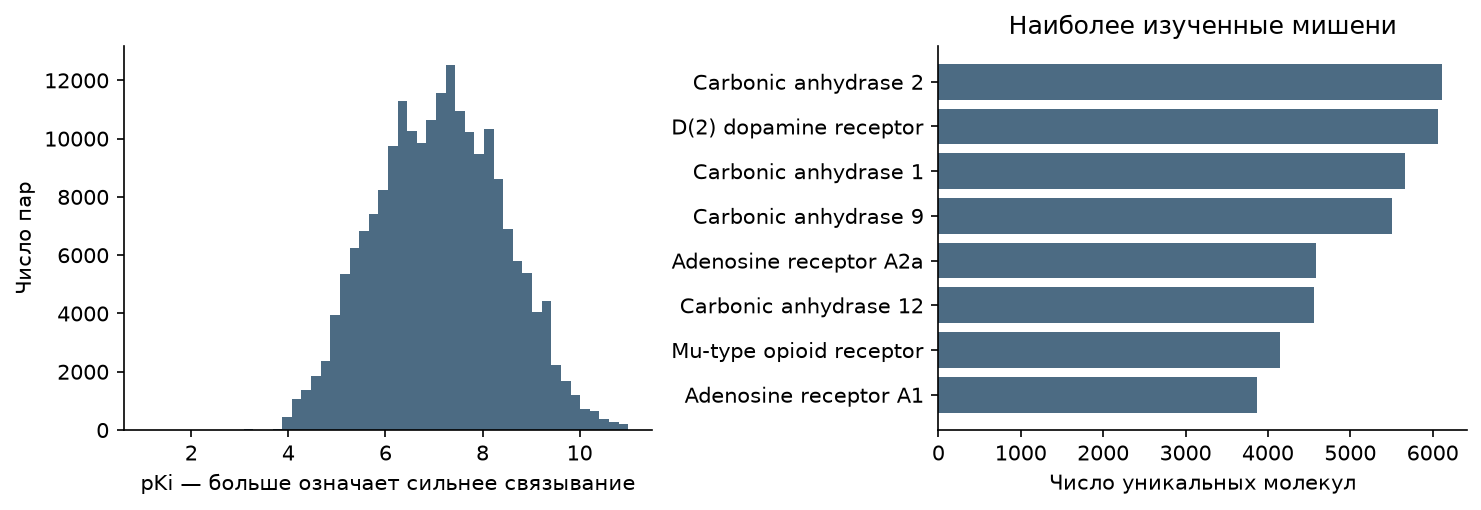

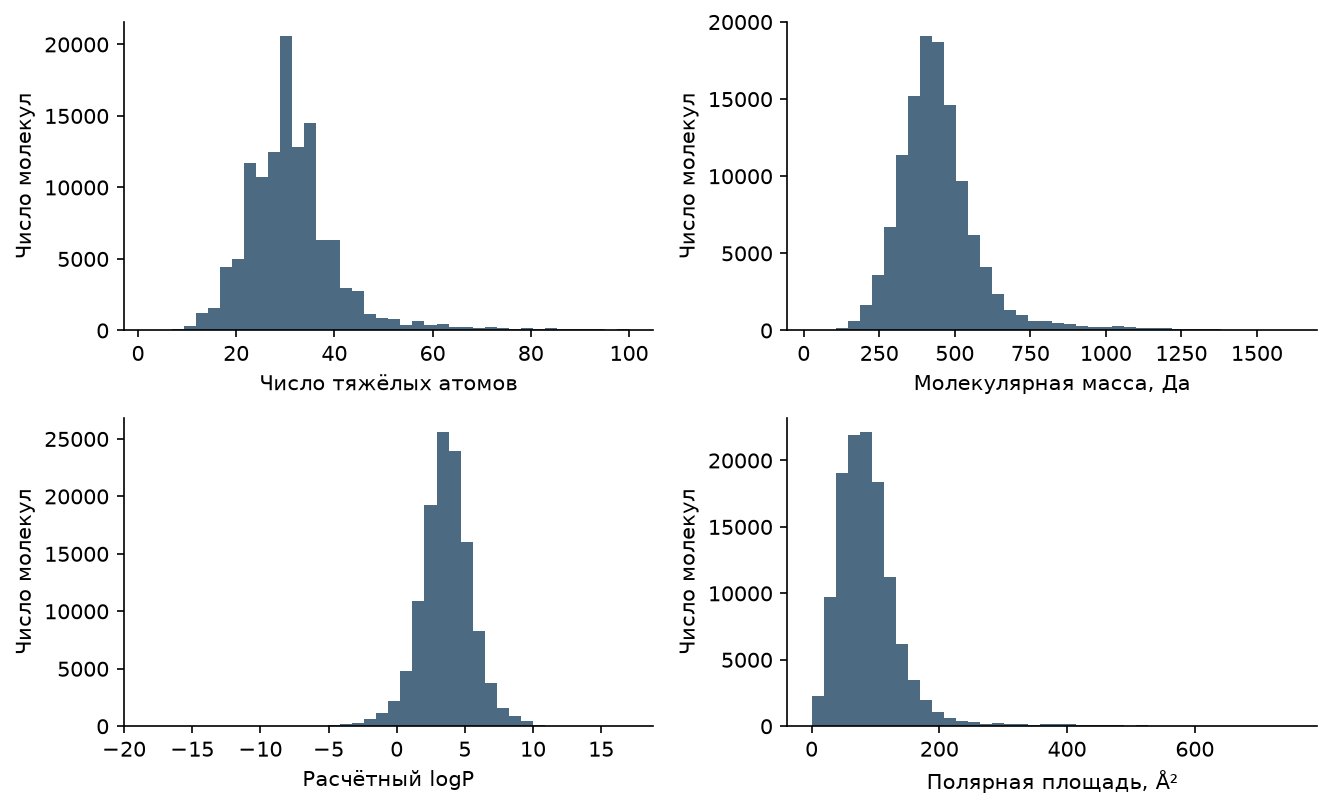

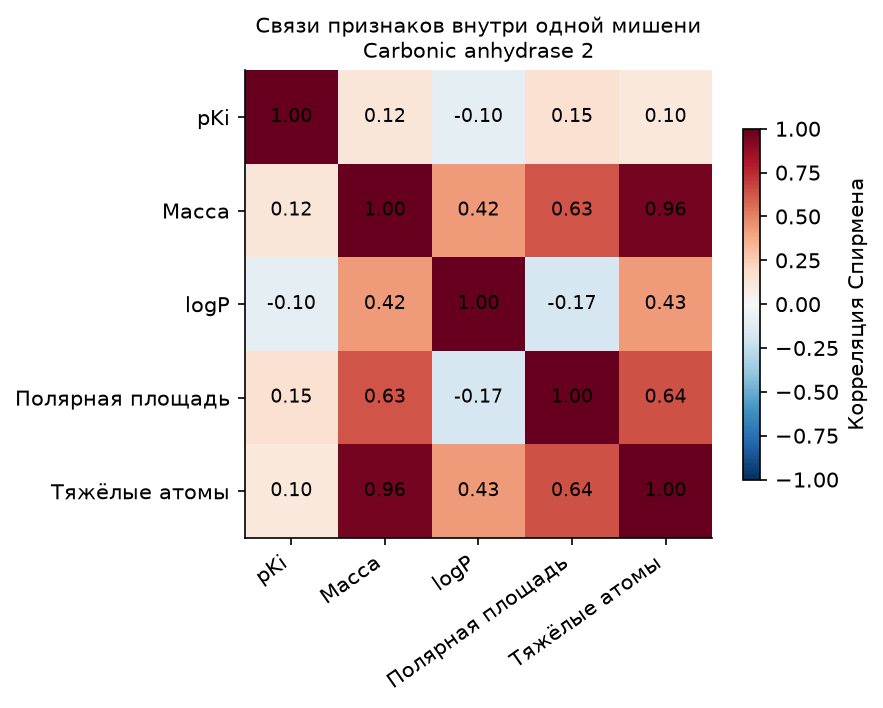

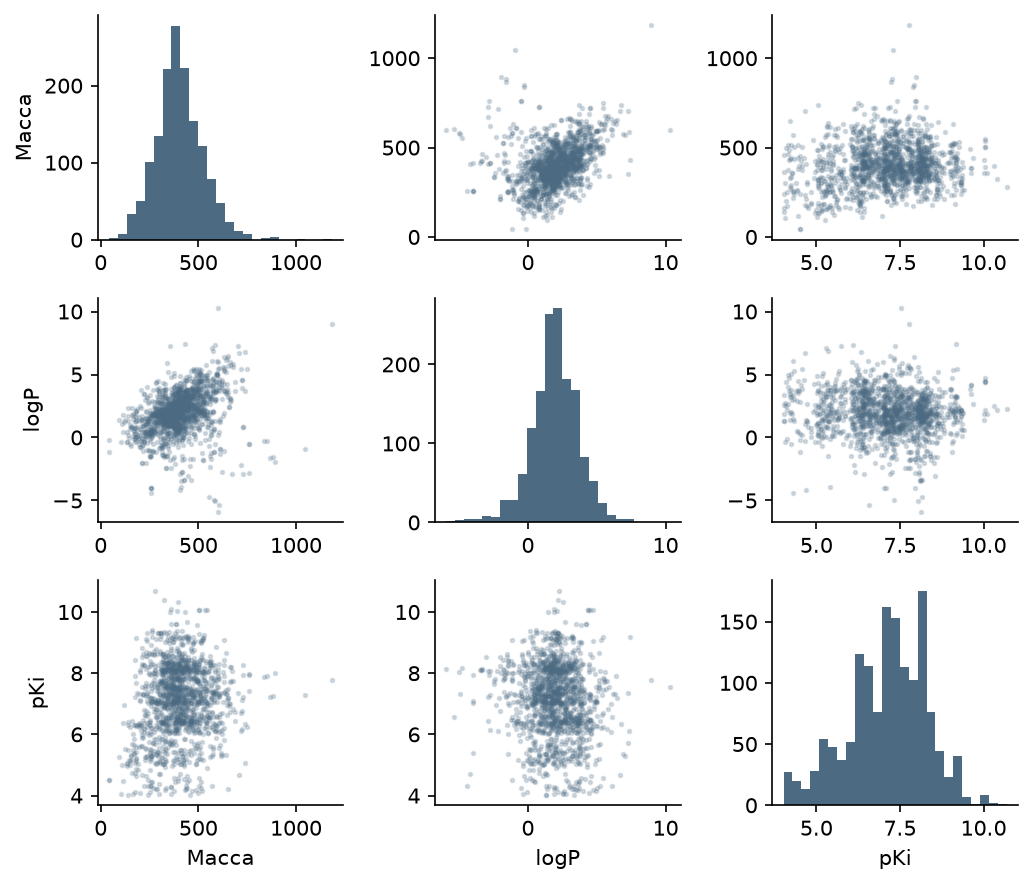

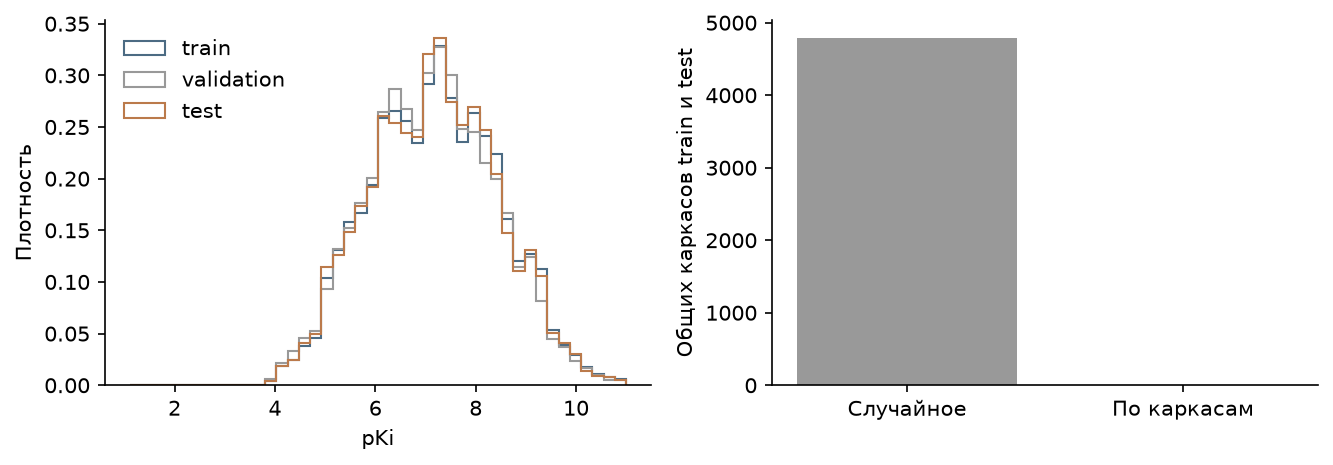

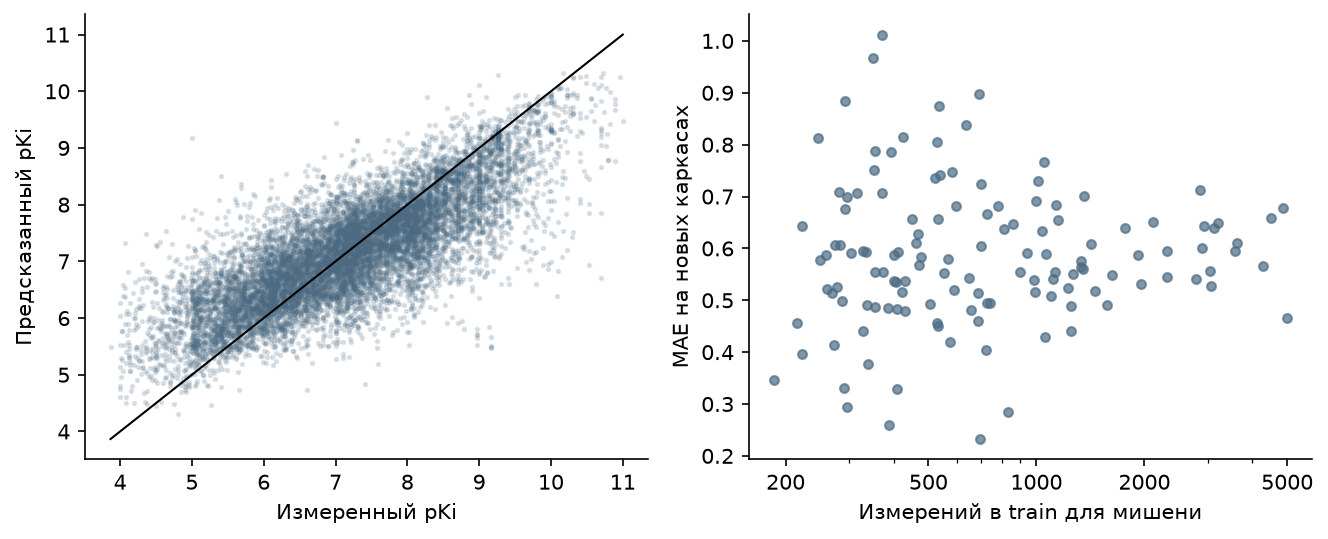

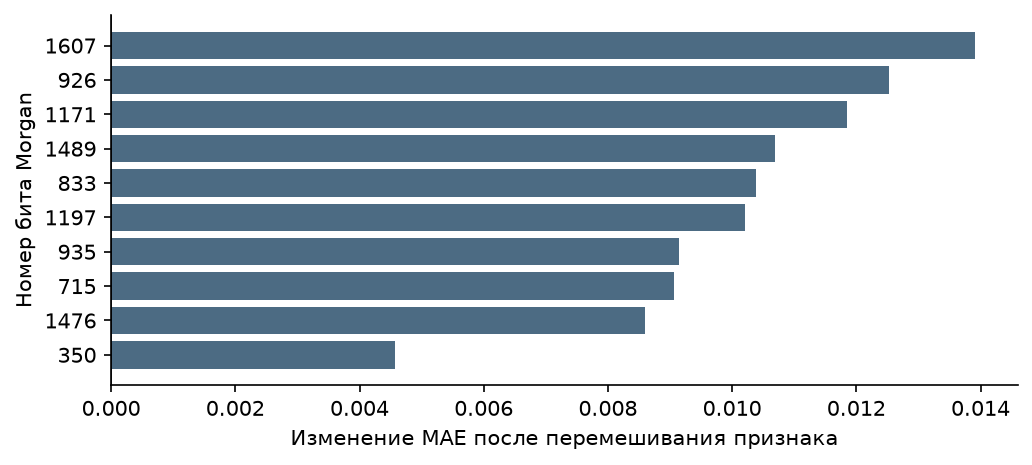

In [12]:
generate_figures(pairs, molecules, eda, baseline)
for filename in ['01_affinity_and_targets.png','02_molecule_properties.png','03_correlations.png',
                 '04_pairplot.png','05_splits.png','06_prediction_errors.png','07_feature_importance.png']:
    display(Image(filename=str(RESULTS / 'figures' / filename)))

Корреляции и попарные распределения с pKi показаны внутри одной мишени, чтобы не смешивать разные белки. В этом примере отдельные дескрипторы слабо связаны с pKi (|ρ| ≤ 0,15). Общая корреляция размера молекулы с активностью могла бы отражать различия изученных наборов, а не универсальное правило.

## Выводы и следующий этап

In [13]:
difference = baseline['dummy_test_macro_MAE'] - baseline['test_macro_MAE']
conclusion = ('Лес улучшил MAE относительно среднего по мишени' if difference > 0
              else 'Лес не улучшил MAE относительно среднего по мишени')
display(Markdown(f"- После очистки осталось **{eda['curated_pairs']:,} пар**; "
                 f"**число зафиксированных для сравнения мишеней — {eda['benchmark_targets']}**.\n"
                 f"- {conclusion}: разница **{difference:.3f} pKi**. "
                 "Это результат на новых каркасах, а не оценка эффективности лечения.\n"
                 "- Покрытие мишеней неравномерно. Будущую многозадачную GNN сравниваем "
                 "на тех же 131 мишени и разбиениях, отдельно проверяя пользу для небольших задач. "
                 "Обучение на дополнительных мишенях — отдельный эксперимент.\n"
                 "- Пропуски активности не являются отрицательными метками. "
                 "Шум измерений и противоречивые повторы требуют отдельного контроля.\n"
                 "- Этот бейзлайн поддерживает известный набор мишеней. "
                 "Для переноса на новые белки потребуется модель, использующая их признаки.\n"
                 "- Практическая ценность и ограничения описаны в [одностраничном PDF]"
                 "(output/pdf/practical_value.pdf)."))

- После очистки осталось **204,676 пар**; **число зафиксированных для сравнения мишеней — 131**.
- Лес улучшил MAE относительно среднего по мишени: разница **0.367 pKi**. Это результат на новых каркасах, а не оценка эффективности лечения.
- Покрытие мишеней неравномерно. Будущую многозадачную GNN сравниваем на тех же 131 мишени и разбиениях, отдельно проверяя пользу для небольших задач. Обучение на дополнительных мишенях — отдельный эксперимент.
- Пропуски активности не являются отрицательными метками. Шум измерений и противоречивые повторы требуют отдельного контроля.
- Этот бейзлайн поддерживает известный набор мишеней. Для переноса на новые белки потребуется модель, использующая их признаки.
- Практическая ценность и ограничения описаны в [одностраничном PDF](output/pdf/practical_value.pdf).

## Воспроизведение и источники

Python 3.12, версии библиотек — `requirements.txt`. Код очистки и экспериментов — `src/affinity_eda.py`; параметры — `config/eda.json`; зафиксированные данные и разбиения — `data/processed/`; метрики, предсказания и проверки — `results/`. В `results/manifest.json` записаны контрольные суммы. Сырые ответы API сохраняются локально и повторно используются; для новой выгрузки нужен интернет.

- [ChEMBL API](https://chembl.gitbook.io/chembl-interface-documentation/web-services/chembl-data-web-services)
- [Типы измерений ChEMBL](https://chembl.gitbook.io/chembl-interface-documentation/frequently-asked-questions/chembl-data-questions)
- [Morgan fingerprints в RDKit](https://www.rdkit.org/docs/GettingStartedInPython.html#morgan-fingerprints-circular-fingerprints)
- [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html)

Требования чекпойнта: EDA для DL и Research, базовая модель, интерпретация, проверка аугментаций и отдельный PDF о практической ценности.